# 1. Hiểu dữ liệu và phân tích khám phá (EDA)

**Môn:** Khai phá dữ liệu  |  **Bộ dữ liệu:** *Credit Score Classification* (Kaggle) – `train.csv`

## Mục tiêu của bài
Dự đoán **điểm tín dụng** (`Credit_Score` ∈ {Poor, Standard, Good}) của khách hàng ngân hàng từ hồ sơ tài chính hằng tháng.

Bài làm theo quy trình **KDD / CRISP-DM**:

| Giai đoạn | Notebook | Đầu ra |
|---|---|---|
| Hiểu dữ liệu | **1_data_understanding_eda** (notebook này) | Bằng chứng về từng lỗi dữ liệu, kế hoạch làm sạch |
| Chuẩn bị dữ liệu | 2_data_cleaning | `data/credit_clean.csv`, báo cáo chất lượng |
| Kiểm định & tạo đặc trưng | 3_post_cleaning_features | `data/credit_features.csv` |
| Mô hình hóa & đánh giá | 4_modeling_evaluation | Kết quả, so sánh, phân tích lỗi |

## Nguyên tắc của notebook này
1. **Chỉ phân tích, không sửa dữ liệu gốc.** Mỗi lỗi đều phải có *bằng chứng định lượng* trước khi đưa ra quyết định xử lý.
2. Mọi ngưỡng/luật dùng ở notebook 2 đều được **rút ra từ dữ liệu ở đây** (không đặt tùy ý).
3. Kết thúc bằng bảng *phát hiện → bằng chứng → quyết định* (mục 1.10).

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import credit_cleaning as cc            # chỉ dùng để XEM dữ liệu đã bỏ giá trị rác; notebook này không sửa dữ liệu gốc
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 170); pd.set_option('display.max_colwidth', 60)
ORDER = ['Poor', 'Standard', 'Good']
PAL = {'Poor': '#c0392b', 'Standard': '#f39c12', 'Good': '#27ae60'}
RAW = '../data/train.csv'
df = pd.read_csv(RAW, low_memory=False)
print(f'{df.shape[0]:,} dòng × {df.shape[1]} cột  |  bộ nhớ {df.memory_usage(deep=True).sum()/1e6:.0f} MB')
df.head(3).T

100,000 dòng × 28 cột  |  bộ nhớ 126 MB


,0,1,2
ID,0x1602,0x1603,0x1604
Customer_ID,CUS_0xd40,CUS_0xd40,CUS_0xd40
Month,January,February,March
Name,Aaron Maashoh,Aaron Maashoh,Aaron Maashoh
Age,23,23,-500
SSN,821-00-0265,821-00-0265,821-00-0265
Occupation,Scientist,Scientist,Scientist
Annual_Income,19114.12,19114.12,19114.12
Monthly_Inhand_Salary,1824.843333,NaN,NaN
Num_Bank_Accounts,3,3,3


## 1.1 Từ điển dữ liệu
Đọc kỹ ý nghĩa từng cột trước khi phân tích. Cột "Hành vi theo thời gian" là **giả thuyết ban đầu** (sẽ kiểm chứng ở mục 1.7).

| Cột | Ý nghĩa | Kiểu đúng | Hành vi theo thời gian (giả thuyết) |
|---|---|---|---|
| `ID` | Mã bản ghi (khách × tháng) | định danh | duy nhất |
| `Customer_ID` | Mã khách hàng | định danh | hằng số |
| `Month` | Tháng (January–August) | thứ tự | tăng dần |
| `Name`, `SSN` | Tên, số an sinh xã hội | định danh | hằng số |
| `Age` | Tuổi | số nguyên | gần như hằng số |
| `Occupation` | Nghề nghiệp | phân loại | hằng số |
| `Annual_Income` | Thu nhập năm | số thực | hằng số |
| `Monthly_Inhand_Salary` | Lương thực nhận hằng tháng | số thực | ? |
| `Num_Bank_Accounts`, `Num_Credit_Card` | Số tài khoản, số thẻ | số nguyên | ? |
| `Interest_Rate` | Lãi suất (%) | số nguyên | hằng số |
| `Num_of_Loan`, `Type_of_Loan` | Số khoản vay, danh sách loại vay | số nguyên, chuỗi | hằng số |
| `Delay_from_due_date` | Số ngày trễ so với hạn thanh toán | số nguyên | biến động |
| `Num_of_Delayed_Payment` | Số lần trả chậm | số nguyên | biến động |
| `Changed_Credit_Limit` | % thay đổi hạn mức tín dụng | số thực | biến động |
| `Num_Credit_Inquiries` | Số lần truy vấn tín dụng | số nguyên | biến động |
| `Credit_Mix` | Chất lượng cơ cấu tín dụng (Bad/Standard/Good) | phân loại có thứ tự | hằng số |
| `Outstanding_Debt` | Dư nợ còn lại | số thực | hằng số |
| `Credit_Utilization_Ratio` | Tỷ lệ sử dụng hạn mức (%) | số thực | biến động |
| `Credit_History_Age` | Tuổi lịch sử tín dụng ("22 Years and 9 Months") | số tháng (đang là chuỗi) | tăng 1 tháng/tháng |
| `Payment_of_Min_Amount` | Có trả mức tối thiểu không (Yes/No/NM) | phân loại | biến động |
| `Total_EMI_per_month` | Tổng tiền trả góp hằng tháng | số thực | ? |
| `Amount_invested_monthly` | Số tiền đầu tư hằng tháng | số thực | biến động |
| `Payment_Behaviour` | Thói quen chi tiêu × giá trị thanh toán | phân loại | biến động |
| `Monthly_Balance` | Số dư cuối tháng | số thực | biến động |
| **`Credit_Score`** | **Nhãn cần dự đoán** | phân loại có thứ tự | biến động? |

## 1.2 Cấu trúc dữ liệu: bảng "panel" khách hàng × tháng

In [2]:
g = df.groupby('Customer_ID')
ssn_ok = df['SSN'].ne('#F%$D@*&8')
panel = pd.Series({
    'Số dòng': f'{len(df):,}',
    'Số khách hàng': f'{df.Customer_ID.nunique():,}',
    'Số dòng mỗi khách': sorted(g.size().unique()),
    'ID duy nhất': bool(df.ID.is_unique),
    'Số dòng trùng hoàn toàn': int(df.duplicated().sum()),
    'Mọi khách có đủ 8 tháng, đúng thứ tự Jan→Aug': bool(g.Month.apply(lambda s: list(s) == cc.MONTHS).all()),
    'Mỗi SSN hợp lệ thuộc đúng 1 khách': bool(df[ssn_ok].groupby('SSN').Customer_ID.nunique().eq(1).all()),
})
panel.to_frame('giá trị')

,giá trị
Số dòng,"100,000"
Số khách hàng,"12,500"
Số dòng mỗi khách,[8]
ID duy nhất,True
Số dòng trùng hoàn toàn,0
"Mọi khách có đủ 8 tháng, đúng thứ tự Jan→Aug",True
Mỗi SSN hợp lệ thuộc đúng 1 khách,True


**Phát hiện.** Dữ liệu không phải 100.000 quan sát độc lập mà là **12.500 khách hàng × 8 tháng**. Hệ quả quan trọng:
- Các dòng của cùng một khách rất giống nhau → khi chia train/test **phải chia theo khách hàng**, nếu không sẽ rò rỉ thông tin (notebook 4).
- Các tháng còn lại của chính khách đó là **nguồn thông tin tốt nhất để sửa ô lỗi** (notebook 2).

### Nhãn `Credit_Score`

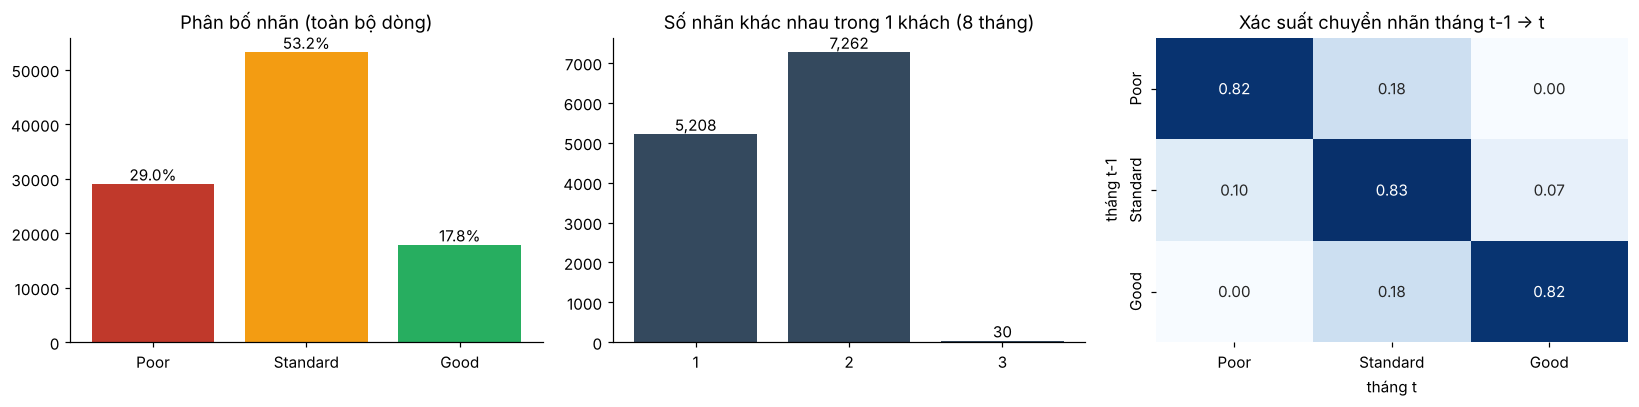

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cnt = df.Credit_Score.value_counts().reindex(ORDER)
ax[0].bar(cnt.index, cnt.values, color=[PAL[k] for k in cnt.index]); ax[0].set_title('Phân bố nhãn (toàn bộ dòng)')
for i, v in enumerate(cnt.values): ax[0].text(i, v, f'{v/len(df):.1%}', ha='center', va='bottom')

n_lab = g.Credit_Score.nunique().value_counts().sort_index()
ax[1].bar(n_lab.index.astype(str), n_lab.values, color='#34495e'); ax[1].set_title('Số nhãn khác nhau trong 1 khách (8 tháng)')
for i, v in enumerate(n_lab.values): ax[1].text(i, v, f'{v:,}', ha='center', va='bottom')

prev = g.Credit_Score.shift(1)
trans = pd.crosstab(prev, df.Credit_Score, normalize='index').reindex(index=ORDER, columns=ORDER)
sns.heatmap(trans, annot=True, fmt='.2f', cmap='Blues', ax=ax[2], cbar=False)
ax[2].set_title('Xác suất chuyển nhãn tháng t-1 → t'); ax[2].set_xlabel('tháng t'); ax[2].set_ylabel('tháng t-1')
plt.tight_layout(); plt.show()

**Phát hiện.**
- Nhãn **lệch lớp**: Standard chiếm hơn một nửa, Good chỉ khoảng 18% → cần dùng *macro-F1* và xét `class_weight` khi mô hình hóa.
- Nhãn **thay đổi theo tháng** trong cùng một khách (đa số khách có 2 nhãn khác nhau) và có tính bền vững cao (đường chéo của ma trận chuyển ≥ 0,8). → Bài toán là dự đoán **nhãn của từng dòng (khách-tháng)**, không phải một nhãn cho cả khách.

## 1.3 Chất lượng dữ liệu – chiều 1: Đầy đủ (giá trị thiếu)

,số ô thiếu,% thiếu
Monthly_Inhand_Salary,15002,15.00
Type_of_Loan,11408,11.41
Name,9985,9.98
Credit_History_Age,9030,9.03
Num_of_Delayed_Payment,7002,7.00
Amount_invested_monthly,4479,4.48
Num_Credit_Inquiries,1965,1.96
Monthly_Balance,1200,1.20


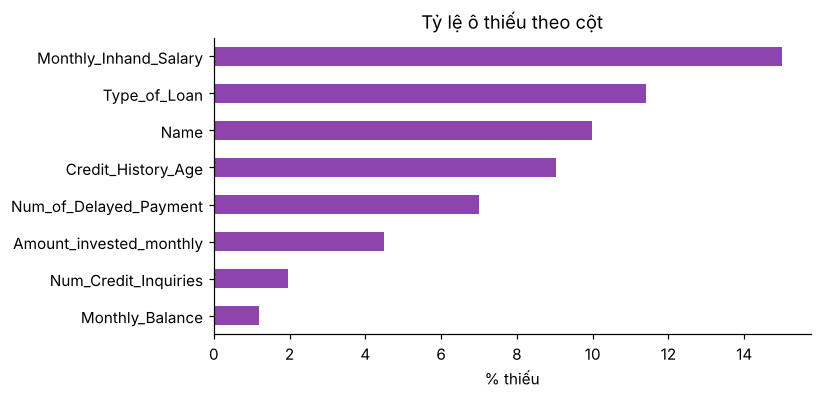

In [4]:
miss = pd.DataFrame({'số ô thiếu': df.isna().sum(), '% thiếu': (df.isna().mean() * 100).round(2)})
miss = miss[miss['số ô thiếu'] > 0].sort_values('số ô thiếu', ascending=False)
display(miss)
ax = miss['% thiếu'].sort_values().plot(kind='barh', figsize=(7, 3.5), color='#8e44ad'); ax.set_xlabel('% thiếu'); ax.set_title('Tỷ lệ ô thiếu theo cột'); plt.show()

**Cột `Type_of_Loan` thiếu 11.408 ô – đây có phải dữ liệu bị mất không?** Kiểm tra theo khách hàng và đối chiếu với `Num_of_Loan`:

In [5]:
per_cust = df.groupby('Customer_ID').agg(n_type_missing=('Type_of_Loan', lambda s: s.isna().sum()),
                                         num_loan=('Num_of_Loan', lambda s: pd.to_numeric(s.astype(str).str.strip('_'), errors='coerce').median()))
print('Phân bố số tháng thiếu Type_of_Loan trong mỗi khách:', per_cust.n_type_missing.value_counts().to_dict())
print('Với các khách thiếu cả 8 tháng, Num_of_Loan (trung vị) =', per_cust[per_cust.n_type_missing == 8].num_loan.value_counts().to_dict())

Phân bố số tháng thiếu Type_of_Loan trong mỗi khách: {0: 11074, 8: 1426}
Với các khách thiếu cả 8 tháng, Num_of_Loan (trung vị) = {0.0: 1426}


**Kết luận:** `Type_of_Loan` hoặc thiếu ở **cả 8 tháng** (1.426 khách) hoặc không thiếu tháng nào, và các khách này đều có `Num_of_Loan = 0`. Vậy ô trống nghĩa là **"không có khoản vay"**, không phải dữ liệu bị mất → điền `No Loan`, không điền bằng giá trị phổ biến.

**Giá trị thiếu có làm lệch nhãn không?** Nếu ô thiếu xuất hiện ngẫu nhiên, tỷ lệ nhãn của các dòng thiếu phải giống các dòng còn lại (kiểm định χ²):

In [6]:
rows = []
for c in miss.index:
    ct = pd.crosstab(df[c].isna(), df.Credit_Score)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    share = (ct.loc[True] / ct.loc[True].sum()).reindex(ORDER); base = (ct.sum() / ct.values.sum()).reindex(ORDER)
    rows.append({'cột': c, 'p-value χ²': round(p, 3), 'lệch tối đa tỷ lệ nhãn (điểm %)': round((share - base).abs().max() * 100, 2)})
pd.DataFrame(rows).set_index('cột')

,p-value χ²,lệch tối đa tỷ lệ nhãn (điểm %)
cột,,
Monthly_Inhand_Salary,0.118,0.60
Type_of_Loan,0.000,17.29
Name,0.543,0.40
Credit_History_Age,0.881,0.25
Num_of_Delayed_Payment,0.795,0.35
Amount_invested_monthly,0.209,1.29
Num_Credit_Inquiries,0.700,0.92
Monthly_Balance,0.027,2.84


Với **7 trong 8 cột**, độ lệch tỷ lệ nhãn giữa dòng thiếu và dòng đầy đủ chỉ ≤ ~1,3 điểm phần trăm (p > 0,05, riêng `Monthly_Balance` lệch 2,8 điểm) → ô thiếu **gần như không phụ thuộc vào nhãn**; việc điền thiếu không tạo thiên lệch có hệ thống theo nhãn. Đây cũng là điều kiện để thí nghiệm "che 10% giá trị" ở notebook 2 là đại diện hợp lệ.

**Ngoại lệ duy nhất là `Type_of_Loan`** (lệch 17 điểm, p ≈ 0): đúng như phân tích ở trên, ô trống nghĩa là *không có khoản vay* – bản thân điều này liên quan tới nhãn – nên cần giữ thành một giá trị riêng (`No Loan`) chứ không điền bằng giá trị khác.

## 1.4 Chất lượng dữ liệu – chiều 2: Đúng định dạng (kiểu dữ liệu & giá trị giả)

### 1.4.1 Cột số bị lưu thành chữ

In [7]:
print(df.dtypes.astype(str).value_counts().to_string(), '\n')
is_num = lambda s: s.dropna().astype(str).str.fullmatch(r'-?\d+(\.\d+)?')
rows = []
for c in cc.NUMERIC_TEXT_COLS:
    s = df[c].dropna(); bad = s[~is_num(s)]
    underscore = s.astype(str).str.contains('_').sum()
    rows.append({'cột': c, 'dtype': str(df[c].dtype), 'ô không phải số': len(bad), 'ô chứa "_"': int(underscore),
                 'ví dụ': bad.value_counts().head(3).index.tolist()})
pd.DataFrame(rows).set_index('cột')

str        20
float64     4
int64       4 



,dtype,ô không phải số,"ô chứa ""_""",ví dụ
cột,,,,
Age,str,4939,4939,"[24_, 38_, 29_]"
Annual_Income,str,6980,6980,"[14388.79_, 42904.26_, 9275.95_]"
Num_of_Loan,str,4785,4785,"[2_, 4_, 3_]"
Num_of_Delayed_Payment,str,2744,2744,"[8_, 15_, 10_]"
Changed_Credit_Limit,str,2091,2091,[_]
Outstanding_Debt,str,1009,1009,"[396.97_, 1054.86_, 761.18_]"
Amount_invested_monthly,str,4305,4305,[__10000__]
Monthly_Balance,str,9,9,[__-333333333333333333333333333__]


Các cột như `Age`, `Annual_Income`… lẽ ra là số nhưng đang là chuỗi vì có dấu `_` dính vào (`'24_'`, `'14388.79_'`). Kiểm tra giả thuyết **"dấu `_` ở đầu/cuối là nguyên nhân duy nhất"**: bỏ `_` rồi ép kiểu, ngoài các giá trị giả đã biết còn ô nào không đọc được không?

In [8]:
rows = []
for c in cc.NUMERIC_TEXT_COLS:
    stripped = pd.to_numeric(df[c].astype('string').str.replace(r'^_+|_+$', '', regex=True), errors='coerce')
    leftover = df[c].notna() & stripped.isna() & (df[c] != cc.PLACEHOLDERS.get(c, '@@'))
    rows.append({'cột': c, 'ô vẫn không đọc được sau khi bỏ "_" (trừ placeholder)': int(leftover.sum())})
pd.DataFrame(rows).set_index('cột')

,"ô vẫn không đọc được sau khi bỏ ""_"" (trừ placeholder)"
cột,
Age,0
Annual_Income,0
Num_of_Loan,0
Num_of_Delayed_Payment,0
Changed_Credit_Limit,0
Outstanding_Debt,0
Amount_invested_monthly,0
Monthly_Balance,0


→ **Bằng 0 ở mọi cột**: bỏ dấu `_` là đủ để ép kiểu (làm ở notebook 2, *sau* khi xử lý placeholder).

### 1.4.2 Giá trị giả (placeholder)
Placeholder là giá trị *trông như dữ liệu* nhưng vô nghĩa. Dùng 3 cách phát hiện độc lập:
1. **Quét chuỗi không chứa chữ cái nào** ở cột phân loại (giá trị thật như `Lawyer`, `Low_spent_Small_value_payments` luôn có chữ);
2. **Kiểm tra định dạng** (SSN phải có dạng `ddd-dd-dddd`);
3. **Tìm giá trị lặp bất thường** ở cột số liên tục (một giá trị thực lặp hàng nghìn lần là không tự nhiên) và giá trị **bất khả về độ lớn**.

In [9]:
# Cách 1: chuỗi không chứa chữ cái nào ở cột phân loại
sym = {}
for c in ['Name', 'Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Type_of_Loan']:
    vc = df[c].dropna().astype(str)
    hit = vc[vc.str.fullmatch(r'[^A-Za-z]+')].value_counts()          # chuỗi không chứa chữ cái nào
    if len(hit): sym[c] = hit.to_dict()
print('Cách 1 – chuỗi không chứa chữ cái:', sym)

# Cách 2: SSN đúng định dạng?
ssn_bad = df.SSN.dropna()[~df.SSN.dropna().str.fullmatch(r'\d{3}-\d{2}-\d{4}')]
print('Cách 2 – SSN sai định dạng:', len(ssn_bad), 'dòng, các giá trị khác nhau:', ssn_bad.unique().tolist())

# Cách 3: giá trị lặp bất thường ở cột số
rows = []
for c in ['Amount_invested_monthly', 'Monthly_Balance', 'Changed_Credit_Limit', 'Outstanding_Debt', 'Annual_Income', 'Monthly_Inhand_Salary']:
    vc = df[c].dropna().astype(str).value_counts()
    rows.append({'cột': c, 'giá trị lặp nhiều nhất': vc.index[0], 'số lần': int(vc.iloc[0]), 'số lần của giá trị thứ 2': int(vc.iloc[1])})
print('\nCách 3 – giá trị lặp nhiều nhất của từng cột số:'); pd.DataFrame(rows).set_index('cột')

Cách 1 – chuỗi không chứa chữ cái: {'Occupation': {'_______': 7062}, 'Credit_Mix': {'_': 20195}, 'Payment_Behaviour': {'!@9#%8': 7600}}
Cách 2 – SSN sai định dạng: 5572 dòng, các giá trị khác nhau: ['#F%$D@*&8']



Cách 3 – giá trị lặp nhiều nhất của từng cột số:


,giá trị lặp nhiều nhất,số lần,số lần của giá trị thứ 2
cột,,,
Amount_invested_monthly,__10000__,4305,169
Monthly_Balance,__-333333333333333333333333333__,9,1
Changed_Credit_Limit,_,2091,133
Outstanding_Debt,1360.45,24,23
Annual_Income,17273.83,16,16
Monthly_Inhand_Salary,6082.1875,15,15


In [10]:
# Cách 3 (tiếp): giá trị bất khả về độ lớn ở Monthly_Balance
mb = pd.to_numeric(df.Monthly_Balance.astype('string').str.replace(r'^_+|_+$', '', regex=True), errors='coerce')
print('Monthly_Balance: min =', mb.min(), '| phân vị 1% =', mb.quantile(.01).round(1), '| số dòng < -1e6:', int((mb < -1e6).sum()))

Monthly_Balance: min = -3.333333333333333e+26 | phân vị 1% = 67.7 | số dòng < -1e6: 9


In [11]:
PH_TABLE = pd.DataFrame([
    {'cột': c, 'giá trị giả': t, 'số dòng': int((df[c] == t).sum()), '% dòng': round((df[c] == t).mean() * 100, 2)}
    for c, t in cc.PLACEHOLDERS.items()]).set_index('cột')
PH_TABLE

,giá trị giả,số dòng,% dòng
cột,,,
SSN,#F%$D@*&8,5572,5.57
Occupation,_______,7062,7.06
Credit_Mix,_,20195,20.20
Payment_Behaviour,!@9#%8,7600,7.60
Changed_Credit_Limit,_,2091,2.09
Amount_invested_monthly,__10000__,4305,4.30
Monthly_Balance,__-333333333333333333333333333__,9,0.01


**Phát hiện – 7 cột có giá trị giả**, nhận diện bằng ba cách ở trên:

| Cột | Giá trị giả | Cách phát hiện |
|---|---|---|
| `SSN` | `#F%$D@*&8` | sai định dạng SSN |
| `Occupation` | `_______` | không chứa chữ cái |
| `Credit_Mix` | `_` | không chứa chữ cái |
| `Payment_Behaviour` | `!@9#%8` | không chứa chữ cái |
| `Changed_Credit_Limit` | `_` | không ép được sang số |
| `Amount_invested_monthly` | `__10000__` | giá trị lặp 4.305 lần, gấp nhiều lần mọi giá trị khác |
| `Monthly_Balance` | `__-333…333__` | độ lớn ≈ −3·10²⁶, bất khả với số dư tài khoản |

> **Bẫy cần tránh:** `__10000__` nếu chỉ bỏ dấu `_` sẽ thành số `10000` – *trông như thật*, và là giá trị lặp nhiều nhất trong cột. Vì vậy thứ tự xử lý bắt buộc là: **nhận diện placeholder → rồi mới ép kiểu số**.

Placeholder chiếm tỷ lệ lớn ở một số cột (`Credit_Mix` 20%). Dòng có placeholder có phải một nhóm "đặc biệt" về nhãn không? Nếu có, không được bỏ qua hay gộp bừa:

In [12]:
rows = []
for c in ['Credit_Mix', 'Occupation', 'Payment_Behaviour']:
    is_ph = df[c] == cc.PLACEHOLDERS[c]
    ct = pd.crosstab(is_ph, df.Credit_Score); chi2, p, _, _ = stats.chi2_contingency(ct)
    sh = (ct.loc[True] / ct.loc[True].sum()).reindex(ORDER)
    rows.append({'cột': c, '% dòng là placeholder': round(is_ph.mean() * 100, 1), 'p-value χ²': round(p, 4),
                 **{f'%{k} trong nhóm placeholder': round(v * 100, 1) for k, v in sh.items()}})
base = (df.Credit_Score.value_counts(normalize=True).reindex(ORDER) * 100).round(1)
print('Tỷ lệ nhãn chung:', base.to_dict()); pd.DataFrame(rows).set_index('cột')

Tỷ lệ nhãn chung: {'Poor': 29.0, 'Standard': 53.2, 'Good': 17.8}


,% dòng là placeholder,p-value χ²,%Poor trong nhóm placeholder,%Standard trong nhóm placeholder,%Good trong nhóm placeholder
cột,,,,,
Credit_Mix,20.2,0.8449,29.1,53.0,17.9
Occupation,7.1,0.7127,28.8,53.6,17.6
Payment_Behaviour,7.6,0.4728,29.3,52.5,18.2


Nhóm placeholder của `Credit_Mix`, `Occupation`, `Payment_Behaviour` có phân bố nhãn **gần giống tỷ lệ chung** → placeholder là nhiễu ngẫu nhiên chứ không mang thông tin về nhãn. Vì vậy có thể *khôi phục giá trị thật* (nếu cột có tính bất biến theo khách) mà không làm mất tín hiệu.

## 1.5 Chất lượng dữ liệu – chiều 3: Hợp lệ về giá trị (ngoại lệ vô lý)
Từ đây phân tích trên dữ liệu **đã bỏ placeholder và ép kiểu số** (chỉ để quan sát, dữ liệu gốc `df` không bị sửa).

In [13]:
view = cc.strip_numeric_text(cc.mark_placeholders(cc.add_month_num(df)))
NUM = ['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance']
view[NUM].describe(percentiles=[.01, .5, .99]).T[['count', 'min', '1%', '50%', '99%', 'max']].round(1)

,count,min,1%,50%,99%,max
Age,100000.0,-500.0,14.0,33.0,4112.1,8698.0
Annual_Income,100000.0,7005.9,7536.0,37578.6,179987.3,24198062.0
Monthly_Inhand_Salary,84998.0,303.6,531.9,3093.7,13814.9,15204.6
Num_Bank_Accounts,100000.0,-1.0,0.0,6.0,445.0,1798.0
Num_Credit_Card,100000.0,0.0,1.0,5.0,849.0,1499.0
Interest_Rate,100000.0,1.0,1.0,13.0,2865.0,5797.0
Num_of_Loan,100000.0,-100.0,-100.0,3.0,9.0,1496.0
Delay_from_due_date,100000.0,-5.0,0.0,18.0,61.0,67.0
Num_of_Delayed_Payment,92998.0,-3.0,0.0,14.0,27.0,4397.0
Changed_Credit_Limit,97909.0,-6.5,-1.5,9.4,28.8,37.0


Nhiều cột có `max` lớn gấp hàng nghìn lần phân vị 99%, hoặc `min` âm ở cột đếm: tuổi **-500 đến 8.698**, số tài khoản tới **1.798**, lãi suất tới **5.797 %**, `Num_of_Loan` = **-100**. Đây không phải đặc tính thật. Câu hỏi là **vạch ranh giới "hợp lệ" ở đâu** – và vạch bằng cách nào cho có cơ sở.

### 1.5.1 Phương pháp 1 – Luật tần suất cho cột đếm / phân loại số
Giá trị thật của cột đếm xuất hiện **rất nhiều lần** (vd. "7 tài khoản" có hàng chục nghìn dòng); giá trị rác là số ngẫu nhiên nên mỗi giá trị chỉ xuất hiện vài lần. Luật: **"thân" phân phối** = đoạn giá trị nguyên *liên tiếp* mà mỗi giá trị xuất hiện ≥ 50 lần và chứa giá trị phổ biến nhất; miền hợp lệ là hai đầu của đoạn này (riêng cột đếm: cận dưới tối thiểu 0 vì số đếm không thể âm).

In [14]:
MIN_COUNT = 50
COUNT_COLS = ['Num_Bank_Accounts', 'Num_Credit_Card', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Num_Credit_Inquiries']   # số đếm: không thể âm

def body_run(vc, min_count=MIN_COUNT):
    # Đoạn số nguyên LIÊN TIẾP mà mỗi giá trị xuất hiện >= min_count lần và chứa giá trị phổ biến nhất (= "thân" phân phối)
    ok = set(vc[vc >= min_count].index); mode = vc.idxmax(); lo = hi = mode
    while lo - 1 in ok: lo -= 1
    while hi + 1 in ok: hi += 1
    return lo, hi

DOMAIN_FOUND, rows = {}, []
for c in ['Age', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Num_Credit_Inquiries']:
    vc = view[c].dropna().round().astype(int).value_counts().sort_index()
    lo, hi = body_run(vc)
    if c in COUNT_COLS: lo = max(lo, 0)                 # luật nghiệp vụ: số đếm không âm
    DOMAIN_FOUND[c] = (int(lo), int(hi))
    out = vc[(vc.index < lo) | (vc.index > hi)]
    top = out.sort_values(ascending=False).head(1)
    rows.append({'cột': c, 'miền hợp lệ tìm được': f'[{lo}, {hi}]', 'dòng ngoài miền': int(out.sum()),
                 'số giá trị rác khác nhau': len(out),
                 'giá trị ngoài miền lặp nhiều nhất': f'{top.index[0]} ({int(top.iloc[0])} lần)' if len(top) else '-'})
pd.DataFrame(rows).set_index('cột')

,miền hợp lệ tìm được,dòng ngoài miền,số giá trị rác khác nhau,giá trị ngoài miền lặp nhiều nhất
cột,,,,
Age,"[14, 56]",2781,1685,-500 (886 lần)
Num_Bank_Accounts,"[0, 10]",1345,932,-1 (21 lần)
Num_Credit_Card,"[1, 10]",2320,1169,11 (36 lần)
Interest_Rate,"[1, 34]",2034,1716,498 (4 lần)
Num_of_Loan,"[0, 9]",4348,404,-100 (3876 lần)
Num_of_Delayed_Payment,"[0, 28]",1380,682,-1 (316 lần)
Num_Credit_Inquiries,"[0, 17]",1650,1205,1230 (4 lần)


**Hai điều đáng chú ý trong cột cuối:**
- `Age` có giá trị **-500 lặp 886 lần** và `Num_of_Loan` có **-100 lặp 3.876 lần**: số nguyên ngẫu nhiên không thể lặp nhiều như vậy → đây là **giá trị giả (sentinel) trong cột số**, cùng loại với `__10000__` ở 1.4.2. Chúng không được tính vào "thân" phân phối vì không nằm trong đoạn giá trị liên tiếp.
- `Num_of_Delayed_Payment` có các giá trị âm (-1, -2, -3) xuất hiện hàng trăm lần – số lần trả chậm không thể âm, nên cận dưới được đặt bằng 0 theo luật nghiệp vụ.

Các giá trị rác còn lại (cột cuối của bảng) chỉ lặp vài lần mỗi giá trị – đúng đặc trưng của số ngẫu nhiên.

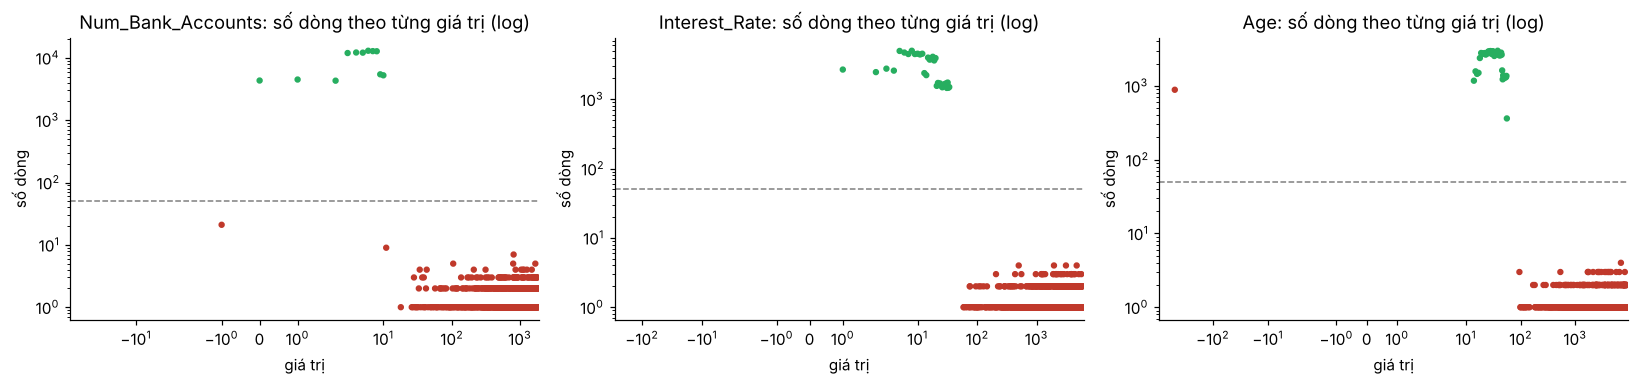

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, c in zip(ax, ['Num_Bank_Accounts', 'Interest_Rate', 'Age']):
    lo_, hi_ = DOMAIN_FOUND[c]
    vc = view[c].dropna().value_counts().sort_index()
    a.scatter(vc.index, vc.values, s=10, c=['#27ae60' if lo_ <= i <= hi_ else '#c0392b' for i in vc.index])
    a.set_yscale('log'); a.set_xscale('symlog'); a.axhline(MIN_COUNT, ls='--', c='gray', lw=1)
    a.set_title(f'{c}: số dòng theo từng giá trị (log)'); a.set_xlabel('giá trị'); a.set_ylabel('số dòng')
plt.tight_layout(); plt.show()

Biểu đồ cho thấy **vách đá**: phần "thân" (xanh) gồm các giá trị lặp hàng nghìn lần, rồi đột ngột chuyển sang "đuôi" (đỏ) gồm các giá trị chỉ xuất hiện 1–4 lần – đúng dấu hiệu của nhiễu ngẫu nhiên. Miền hợp lệ tìm được:

In [16]:
print('Miền tìm được từ dữ liệu :', DOMAIN_FOUND)
print('Miền khai báo trong module :', cc.DOMAIN)
assert DOMAIN_FOUND == cc.DOMAIN, 'Miền trong module phải trùng với miền rút ra từ EDA'
print('→ Trùng khớp ✓')

Miền tìm được từ dữ liệu : {'Age': (14, 56), 'Num_Bank_Accounts': (0, 10), 'Num_Credit_Card': (1, 10), 'Interest_Rate': (1, 34), 'Num_of_Loan': (0, 9), 'Num_of_Delayed_Payment': (0, 28), 'Num_Credit_Inquiries': (0, 17)}
Miền khai báo trong module : {'Age': (14, 56), 'Num_Bank_Accounts': (0, 10), 'Num_Credit_Card': (1, 10), 'Interest_Rate': (1, 34), 'Num_of_Loan': (0, 9), 'Num_of_Delayed_Payment': (0, 28), 'Num_Credit_Inquiries': (0, 17)}
→ Trùng khớp ✓


### 1.5.2 Phương pháp 2 – "Chữ ký định dạng" của giá trị tiêm vào (`Total_EMI_per_month`)
`Total_EMI_per_month` là số thực dài (vd. `49.574949…`). Giả thuyết: giá trị rác là **số nguyên** (vì được sinh ngẫu nhiên khác cơ chế sinh dữ liệu thật). Kiểm tra: tách các giá trị dương theo "có phải số nguyên không" và so sánh độ lớn.

In [17]:
emi = view.Total_EMI_per_month.dropna()
pos = emi[emi > 0]
is_int = pos == pos.round(0)
pd.DataFrame({'số dòng': [int((~is_int).sum()), int(is_int.sum())],
              'nhỏ nhất': [pos[~is_int].min(), pos[is_int].min()],
              'trung vị': [pos[~is_int].median(), pos[is_int].median()],
              'lớn nhất': [pos[~is_int].max(), pos[is_int].max()]},
             index=['số thực (có phần lẻ)', 'số nguyên dương']).round(1)

,số dòng,nhỏ nhất,trung vị,lớn nhất
số thực (có phần lẻ),86223,4.5,76.8,1779.1
số nguyên dương,3164,845.0,41070.0,82331.0


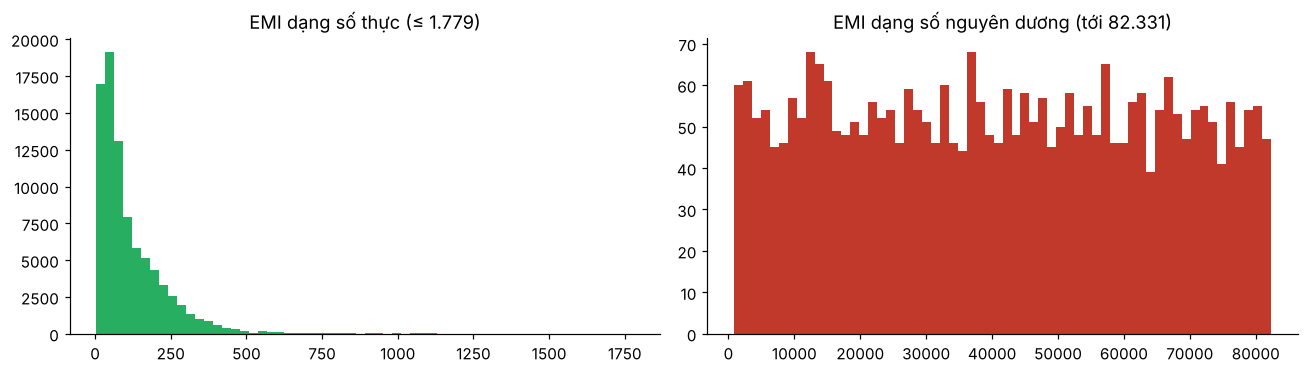

Số EMI = 0 (khách không có khoản trả góp): 10613 → hợp lệ, KHÔNG phải rác


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(pos[~is_int].clip(upper=2000), bins=60, color='#27ae60'); ax[0].set_title('EMI dạng số thực (≤ 1.779)')
ax[1].hist(pos[is_int], bins=60, color='#c0392b'); ax[1].set_title('EMI dạng số nguyên dương (tới 82.331)')
plt.tight_layout(); plt.show()
print('Số EMI = 0 (khách không có khoản trả góp):', int((emi == 0).sum()), '→ hợp lệ, KHÔNG phải rác')

**Phát hiện:** EMI hợp lệ có phần lẻ dài và không vượt 1.779; toàn bộ **3.164 giá trị nguyên dương** (trung vị ~41.000, rải đều tới 82.331) là rác. Luật: *EMI > 1800 hoặc là số nguyên dương → không hợp lệ*. Giá trị `0` là hợp lệ (khách không trả góp).

### 1.5.3 Phương pháp 3 – Nhất quán với chính khách hàng (`Annual_Income`)
Thu nhập thật không đổi trong 8 tháng. Đo độ lệch tương đối của từng giá trị so với **trung vị của chính khách đó**:

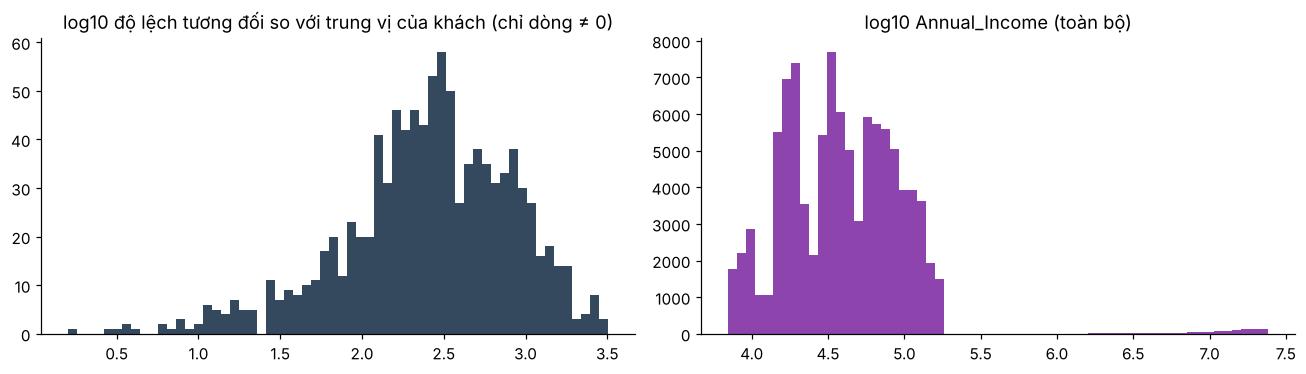

Dòng có độ lệch = 0 (bằng đúng trung vị khách): 99001 | dòng lệch > 50%: 999 | dòng lệch trong (0, 50%]: 0
Các giá trị lệch > 50% có phải số nguyên không?  1.0


In [19]:
med = view.groupby('Customer_ID').Annual_Income.transform('median')
dev = (view.Annual_Income / med - 1).abs()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(np.log10(dev[dev > 0] + 1e-9), bins=60, color='#34495e'); ax[0].set_title('log10 độ lệch tương đối so với trung vị của khách (chỉ dòng ≠ 0)')
ax[1].hist(np.log10(view.Annual_Income.dropna()), bins=60, color='#8e44ad'); ax[1].set_title('log10 Annual_Income (toàn bộ)')
plt.tight_layout(); plt.show()
print('Dòng có độ lệch = 0 (bằng đúng trung vị khách):', int((dev == 0).sum()), '| dòng lệch > 50%:', int((dev > 0.5).sum()), '| dòng lệch trong (0, 50%]:', int(((dev > 0) & (dev <= 0.5)).sum()))
print('Các giá trị lệch > 50% có phải số nguyên không? ', (view.Annual_Income[dev > 0.5] == view.Annual_Income[dev > 0.5].round(0)).mean().round(3))

Độ lệch hoặc **bằng 0** (giá trị đúng) hoặc **rất lớn** (rác, nhiều bậc độ lớn, và hầu hết là số nguyên – cùng chữ ký với EMI rác); gần như không có vùng "lệch vừa phải". Luật: *lệch > 50% so với trung vị của chính khách → không hợp lệ* (999 dòng).

### 1.5.4 Vì sao **không** dùng một luật IQR chung cho mọi cột?
Cách phổ biến là gạt mọi giá trị ngoài `Q3 + k·IQR`. Kiểm tra xem luật này sẽ xóa gì ở các cột **không** có rác (sau khi đã bỏ placeholder):

In [20]:
rows = []
for c in ['Amount_invested_monthly', 'Monthly_Balance', 'Changed_Credit_Limit', 'Delay_from_due_date', 'Outstanding_Debt', 'Monthly_Inhand_Salary', 'Credit_Utilization_Ratio']:
    s = view[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    rows.append({'cột': c, 'max': round(s.max(), 1), 'phân vị 99,9%': round(s.quantile(.999), 1), 'max / phân vị 99,9%': round(s.max() / s.quantile(.999), 2),
                 'IQR k=1,5 sẽ xóa': int(((s > q3 + 1.5 * iqr) | (s < q1 - 1.5 * iqr)).sum()), 'IQR k=3 sẽ xóa': int(((s > q3 + 3 * iqr) | (s < q1 - 3 * iqr)).sum())})
pd.DataFrame(rows).set_index('cột')

,max,"phân vị 99,9%","max / phân vị 99,9%","IQR k=1,5 sẽ xóa",IQR k=3 sẽ xóa
cột,,,,,
Amount_invested_monthly,1977.3,1441.1,1.37,7568,2779
Monthly_Balance,1602.0,1398.3,1.15,7627,1555
Changed_Credit_Limit,37.0,32.5,1.14,668,0
Delay_from_due_date,67.0,65.0,1.03,4002,0
Outstanding_Debt,4998.1,4975.6,1.00,5272,0
Monthly_Inhand_Salary,15204.6,14880.4,1.02,1683,0
Credit_Utilization_Ratio,50.0,45.6,1.10,4,0


Ở 7 cột này `max` chỉ ngang phân vị 99,9% (tỷ lệ ≈ 1,0–1,4) – **không có đuôi rác cô lập**; phần "ngoại lệ" theo IQR chỉ là phần đuôi lệch phải *thật* của phân phối thu nhập/số dư. Nếu áp IQR chung sẽ xóa nhầm hàng nghìn giá trị hợp lệ (đặc biệt `Amount_invested_monthly`, `Monthly_Balance`). → **Chỉ áp luật loại bỏ cho các cột có bằng chứng rác** (mục 1.5.1–1.5.3).

## 1.6 Chất lượng dữ liệu – chiều 4: Nhất quán theo khách hàng & ràng buộc giữa các cột
Dùng dữ liệu đã bỏ placeholder + bỏ giá trị rác (mục 1.5) để thấy cấu trúc thật của từng cột.

In [21]:
v3 = cc.mark_invalid(view)
cols = ['SSN', 'Occupation', 'Name', 'Credit_Mix', 'Outstanding_Debt', 'Annual_Income', 'Interest_Rate', 'Num_of_Loan', 'Age',
        'Num_Bank_Accounts', 'Num_Credit_Card', 'Total_EMI_per_month', 'Monthly_Inhand_Salary',
        'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Delay_from_due_date', 'Credit_Utilization_Ratio',
        'Amount_invested_monthly', 'Monthly_Balance', 'Payment_Behaviour', 'Payment_of_Min_Amount']
gg = v3.groupby('Customer_ID')
nu = pd.DataFrame({c: gg[c].nunique().value_counts().sort_index() for c in cols}).T.fillna(0).astype(int)
nu.columns = [f'{k} giá trị' for k in nu.columns]
nu

,1 giá trị,2 giá trị,3 giá trị,4 giá trị,5 giá trị,6 giá trị,7 giá trị,8 giá trị
SSN,12500,0,0,0,0,0,0,0
Occupation,12500,0,0,0,0,0,0,0
Name,12500,0,0,0,0,0,0,0
Credit_Mix,12500,0,0,0,0,0,0,0
Outstanding_Debt,12500,0,0,0,0,0,0,0
Annual_Income,12500,0,0,0,0,0,0,0
Interest_Rate,12500,0,0,0,0,0,0,0
Num_of_Loan,12500,0,0,0,0,0,0,0
Age,5302,7198,0,0,0,0,0,0
Num_Bank_Accounts,12200,300,0,0,0,0,0,0


Đọc bảng: mỗi hàng là một cột dữ liệu; số trong ô là **số khách hàng** có đúng *k* giá trị phân biệt (hợp lệ) trong 8 tháng.

**Phân loại hành vi theo thời gian (kết quả kiểm chứng giả thuyết 1.1):**
- **Hằng số tuyệt đối** (mọi khách đúng 1 giá trị hợp lệ): `SSN`, `Occupation`, `Name`, `Credit_Mix`, `Outstanding_Debt`, `Annual_Income`, `Interest_Rate`, `Num_of_Loan`. → Ô lỗi có thể khôi phục **chính xác** từ các tháng khác của cùng khách.
- **Hằng số có "bước nhảy"**: `Age` (đổi đúng 1 lần, +1), `Num_Bank_Accounts`, `Num_Credit_Card`, `Total_EMI_per_month`, `Monthly_Inhand_Salary` – vài trăm khách có đúng 2 mức. Cần xem đây là lỗi hay thay đổi thật.
- **Biến động theo tháng**: các cột còn lại.

### Các "bước nhảy" là thay đổi thật hay lỗi?

In [22]:
changed = {c: set(gg[c].nunique()[lambda s: s > 1].index) for c in ['Num_Bank_Accounts', 'Num_Credit_Card', 'Total_EMI_per_month', 'Monthly_Inhand_Salary']}
print('Số khách có thay đổi:', {c: len(s) for c, s in changed.items()})
print('Khách thay đổi CẢ Num_Bank_Accounts và Num_Credit_Card :', len(changed['Num_Bank_Accounts'] & changed['Num_Credit_Card']))
print('Khách thay đổi CẢ Total_EMI_per_month và Monthly_Inhand_Salary:', len(changed['Total_EMI_per_month'] & changed['Monthly_Inhand_Salary']))
ex = sorted(changed['Num_Bank_Accounts'])[:1] + sorted(changed['Monthly_Inhand_Salary'] - changed['Num_Bank_Accounts'])[:1]
for i in ex:
    print(f'\n{i}'); display(v3.loc[v3.Customer_ID == i, ['Month', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Monthly_Inhand_Salary', 'Total_EMI_per_month']].T)

Số khách có thay đổi: {'Num_Bank_Accounts': 300, 'Num_Credit_Card': 296, 'Total_EMI_per_month': 772, 'Monthly_Inhand_Salary': 746}
Khách thay đổi CẢ Num_Bank_Accounts và Num_Credit_Card : 289
Khách thay đổi CẢ Total_EMI_per_month và Monthly_Inhand_Salary: 741

CUS_0x10dd


,16008,16009,16010,16011,16012,16013,16014,16015
Month,January,February,March,April,May,June,July,August
Num_Bank_Accounts,5.0,5.0,5.0,4.0,4.0,4.0,4.0,4.0
Num_Credit_Card,4.0,4.0,4.0,3.0,3.0,3.0,3.0,3.0
Monthly_Inhand_Salary,9090.8,9090.8,9090.8,9090.8,9090.8,9090.8,9090.8,9090.8
Total_EMI_per_month,315.406101,315.406101,315.406101,315.406101,315.406101,315.406101,315.406101,315.406101



CUS_0x105b


,5800,5801,5802,5803,5804,5805,5806,5807
Month,January,February,March,April,May,June,July,August
Num_Bank_Accounts,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
Num_Credit_Card,4.0,4.0,NaN,4.0,4.0,4.0,4.0,4.0
Monthly_Inhand_Salary,2575.0175,2575.0175,2575.0175,2575.0175,2575.0175,2289.5937,2289.5937,2289.5937
Total_EMI_per_month,0.0,0.0,0.0,NaN,0.0,285.4238,285.4238,285.4238


**Phát hiện quan trọng:** các thay đổi **đi theo cặp và là bước nhảy một lần** (không dao động ngẫu nhiên): số tài khoản và số thẻ cùng đổi (hầu hết các trường hợp), lương và EMI cùng đổi. Đây là *thay đổi thật* (đổi việc, thêm/đóng khoản vay…), không phải lỗi.

**Hệ quả cho cách điền thiếu:** với các cột này, điền bằng *mode/median của khách* sẽ **kéo giá trị của giai đoạn này sang giai đoạn khác**; điền bằng **tháng gần nhất** thì đúng hơn. Điều này được kiểm chứng định lượng ở notebook 2.

### Ràng buộc chéo giữa các cột

In [23]:
# (1) Num_of_Loan phải bằng số loại vay liệt kê trong Type_of_Loan
ok = v3.Num_of_Loan.notna()
cnt = v3.Type_of_Loan.map(cc.count_loan_types)
print(f'(1) Num_of_Loan == số loại vay trong Type_of_Loan: {(cnt[ok] == v3.Num_of_Loan[ok]).mean():.2%} ({ok.sum():,} dòng hợp lệ)')

# (2) Credit_History_Age phải tăng đúng 1 tháng mỗi tháng
hist = v3.Credit_History_Age.map(cc.parse_history_months)
spread = (hist - v3.Month_Num).groupby(v3.Customer_ID).agg(lambda s: s.max() - s.min())
print(f'(2) Credit_History_Age − thứ tự tháng là hằng số trong khách: {(spread == 0).mean():.2%} số khách')

# (3) Tuổi thay đổi tối đa 1 trong 8 tháng
rng = gg.Age.agg(lambda s: s.max() - s.min())
print(f'(3) Tuổi chênh tối đa trong khách: {rng.value_counts().sort_index().to_dict()}')

# (4) Annual_Income ≈ 12 × Monthly_Inhand_Salary
r = (v3.Monthly_Inhand_Salary * 12 / v3.Annual_Income).dropna()
print(f'(4) 12×Lương thực nhận / Thu nhập năm: trung vị {r.median():.3f}, IQR [{r.quantile(.25):.3f}, {r.quantile(.75):.3f}], 1%–99% [{r.quantile(.01):.2f}, {r.quantile(.99):.2f}]')

(1) Num_of_Loan == số loại vay trong Type_of_Loan: 100.00% (95,652 dòng hợp lệ)


(2) Credit_History_Age − thứ tự tháng là hằng số trong khách: 100.00% số khách


(3) Tuổi chênh tối đa trong khách: {0.0: 5302, 1.0: 7198}
(4) 12×Lương thực nhận / Thu nhập năm: trung vị 0.999, IQR [0.958, 1.039], 1%–99% [0.72, 1.30]


**Kết luận các ràng buộc:**
1. `Num_of_Loan` khớp **100%** với số loại vay → khi `Num_of_Loan` bị rác (4.348 dòng) có thể **suy ra chính xác** từ `Type_of_Loan` thay vì đoán.
2. `Credit_History_Age` tăng **đúng +1 tháng mỗi tháng ở 100% khách** → ô thiếu (9.030) khôi phục **chính xác bằng số học**.
3. Tuổi chỉ đổi tối đa 1 (sinh nhật) → xác nhận miền tuổi 14–56 và cách điền theo tháng gần nhất.
4. `Annual_Income`/12 và `Monthly_Inhand_Salary` quanh 1 (trung vị 0,999; IQR 0,96–1,04): hai cột **tương quan rất mạnh**; đây là bằng chứng độc lập rằng các giá trị thu nhập khổng lồ (1.5.3) là rác.

### Tên khách hàng
Ghi chú: nhiều `Name` có một chữ cái thường dính ở cuối (vd. `Ashleyh`, `Jessicad`). Đây là nhiễu định danh; vì `Name` chỉ là mã định danh và **không dùng làm đặc trưng**, giữ nguyên (chỉ điền ô thiếu theo khách) và ghi nhận như một hạn chế.

In [24]:
g_nm = df.dropna(subset=['Name']).groupby('Customer_ID').Name.nunique()
print('Mỗi khách có đúng 1 Name (khi không thiếu):', bool((g_nm == 1).all()))
print('Số khách có ≥1 tháng thiếu Name:', int(df.groupby('Customer_ID').Name.apply(lambda s: s.isna().any()).sum()), '| số khách thiếu cả 8 tháng:', int(df.groupby('Customer_ID').Name.apply(lambda s: s.isna().all()).sum()))
print(df.Name.dropna().drop_duplicates().sample(8, random_state=3).tolist())

Mỗi khách có đúng 1 Name (khi không thiếu): True


Số khách có ≥1 tháng thiếu Name: 7133 | số khách thiếu cả 8 tháng: 0
['Lucia Mutikaniy', 'Alwyn Scottg', 'Lindaz', 'enu', 'Katen', 'Yukhananovb', 'Maggiel', 'Lauren Tarab']


## 1.7 Phân tích đơn biến & hai biến (với nhãn) trên giá trị hợp lệ
Dùng `v3` (đã bỏ placeholder và giá trị rác, **chưa điền thiếu**). Mỗi đặc trưng được so sánh theo nhãn.

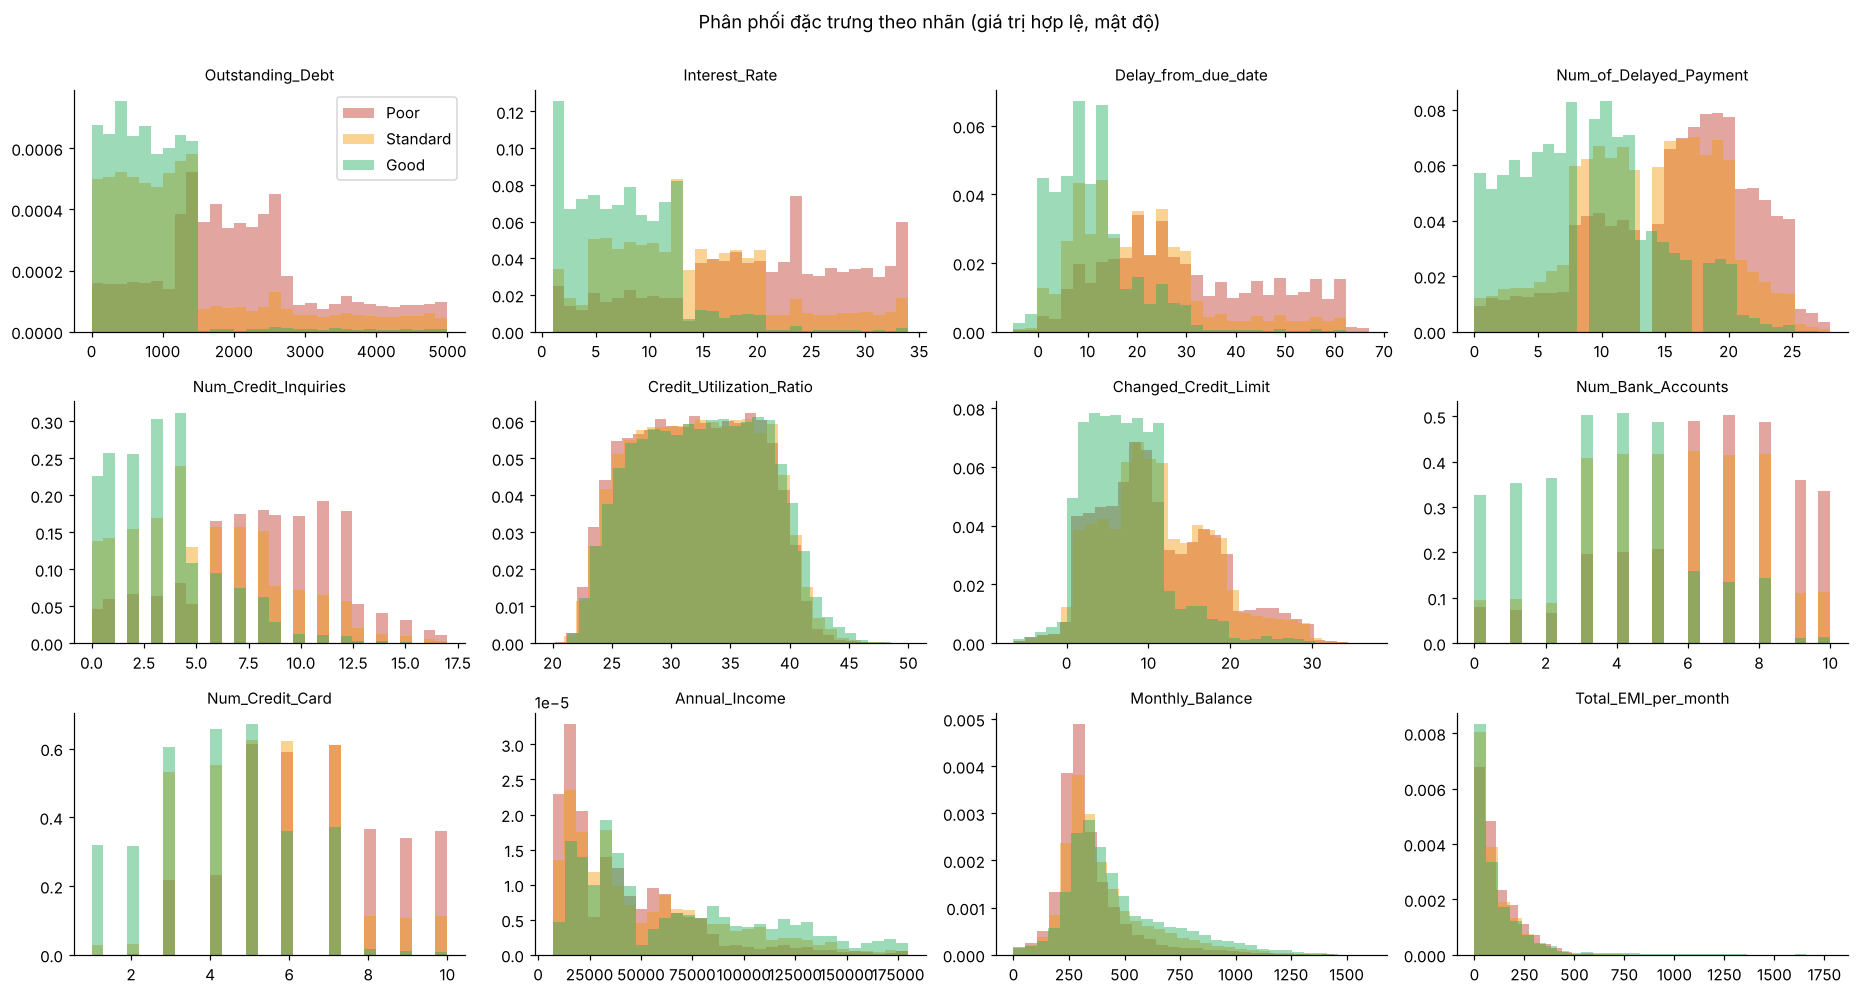

In [25]:
FEATS = ['Outstanding_Debt', 'Interest_Rate', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Num_Credit_Inquiries', 'Credit_Utilization_Ratio',
         'Changed_Credit_Limit', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Annual_Income', 'Monthly_Balance', 'Total_EMI_per_month']
fig, ax = plt.subplots(3, 4, figsize=(17, 9))
for a, c in zip(ax.ravel(), FEATS):
    for k in ORDER:
        s = v3.loc[v3.Credit_Score == k, c].dropna()
        a.hist(s, bins=30, density=True, alpha=.45, color=PAL[k], label=k)
    a.set_title(c, fontsize=10)
ax[0, 0].legend(); plt.suptitle('Phân phối đặc trưng theo nhãn (giá trị hợp lệ, mật độ)', y=1.0); plt.tight_layout(); plt.show()

**Quan sát từ biểu đồ.** Nhiều đặc trưng cho thấy **ngưỡng phân tách khá rõ** giữa các nhãn: `Outstanding_Debt` ≈ 1.500, `Interest_Rate` ≈ 14 và ≈ 20, `Num_of_Delayed_Payment` ≈ 8–10, `Num_Credit_Inquiries` ≈ 5, `Num_Credit_Card` ≥ 8 gần như chỉ còn Poor/Standard. Tuy vậy các phân phối **chồng lấn nhiều**: mỗi đặc trưng thường *loại trừ được một lớp* chứ không *xác định* được nhãn (ví dụ `Interest_Rate` ≥ 21 hầu như không còn Good, ≈ 1%, nhưng vẫn lẫn ≈ 34% Standard). Điều này gợi ý (a) mô hình dạng **cây** hợp vì tín hiệu nằm ở các ngưỡng, (b) nhãn có **nhiễu** nên không thể kỳ vọng độ chính xác rất cao (xác nhận ở notebook 4), (c) dữ liệu mang tính **mô phỏng/tổng hợp** (hạn chế cần nêu), (d) nếu làm sạch sai ở các cột này thì các ngưỡng bị nhòe và mô hình mất tín hiệu. `Credit_Utilization_Ratio`, `Occupation`, `Month` hầu như không phân biệt được các nhãn.

### Mức độ liên hệ với nhãn: kiểm định thống kê và độ lớn hiệu ứng
- **Biến số:** Kruskal–Wallis (không giả định phân phối chuẩn) và độ lớn hiệu ứng ε² = H/(n−1); thêm Spearman với nhãn có thứ tự (Poor < Standard < Good).
- **Biến phân loại:** χ² và hệ số Cramér's V.
Độ lớn hiệu ứng quan trọng hơn p-value vì với 100.000 dòng mọi thứ đều có ý nghĩa thống kê.

In [26]:
def effect_numeric(d, cols):
    rows = []; y = d.Credit_Score; ordinal = y.map({'Poor': 0, 'Standard': 1, 'Good': 2})
    for c in cols:
        m = d[c].notna(); groups = [d.loc[m & (y == k), c] for k in ORDER]
        H, p = stats.kruskal(*groups); n = m.sum()
        rows.append({'đặc trưng': c, 'ε² (Kruskal)': H / (n - 1), 'Spearman với nhãn': stats.spearmanr(d.loc[m, c], ordinal[m])[0], 'n hợp lệ': int(n)})
    return pd.DataFrame(rows).set_index('đặc trưng')

def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

NUM_FEATS = [c for c in NUM if c not in ('Num_of_Loan',)] + ['Num_of_Loan']
eff_num = effect_numeric(v3, NUM_FEATS).sort_values('ε² (Kruskal)', ascending=False)
CAT = ['Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Occupation', 'Month']
eff_cat = pd.DataFrame({'Cramér V': {c: cramers_v(df[c].fillna('(thiếu)'), df.Credit_Score) for c in CAT}}).sort_values('Cramér V', ascending=False)
display(eff_num.round(4)); display(eff_cat.round(4))
eff_num.to_csv('../data/reports/eda_effect_numeric_before.csv'); eff_cat.to_csv('../data/reports/eda_effect_categorical_before.csv')

,ε² (Kruskal),Spearman với nhãn,n hợp lệ
đặc trưng,,,
Interest_Rate,0.2334,-0.4809,97966
Delay_from_due_date,0.1946,-0.4379,100000
Outstanding_Debt,0.1940,-0.4338,100000
Num_Credit_Inquiries,0.1920,-0.4379,96385
Num_Bank_Accounts,0.1575,-0.3874,98655
Num_Credit_Card,0.1487,-0.3850,97680
Num_of_Delayed_Payment,0.1439,-0.3617,91618
Num_of_Loan,0.1248,-0.3531,95652
Changed_Credit_Limit,0.0534,-0.1573,97909


,Cramér V
Credit_Mix,0.4022
Payment_of_Min_Amount,0.3132
Payment_Behaviour,0.0846
Month,0.0318
Occupation,0.0292


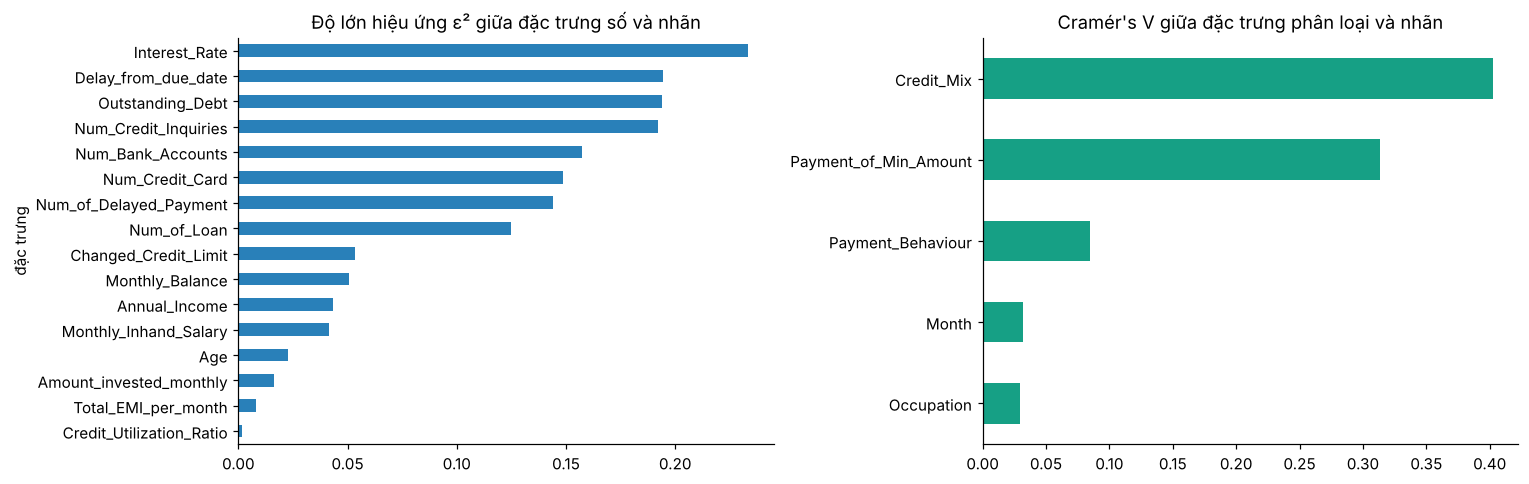

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
eff_num['ε² (Kruskal)'].sort_values().plot(kind='barh', ax=ax[0], color='#2980b9'); ax[0].set_title('Độ lớn hiệu ứng ε² giữa đặc trưng số và nhãn')
eff_cat['Cramér V'].sort_values().plot(kind='barh', ax=ax[1], color='#16a085'); ax[1].set_title("Cramér's V giữa đặc trưng phân loại và nhãn")
plt.tight_layout(); plt.show()

**Phát hiện.** Các đặc trưng liên quan nhiều nhất tới nhãn đều thuộc nhóm **hành vi nợ / thanh toán**: lãi suất, độ trễ thanh toán, số lần trả chậm, nợ tồn đọng, số lần truy vấn tín dụng. Về phân loại, `Credit_Mix` và `Payment_of_Min_Amount` có Cramér's V cao nhất; `Occupation` và `Month` gần như **không** liên quan tới nhãn.

→ Hai điều rút ra: (1) hợp lý với kiến thức tín dụng nên dữ liệu **có tín hiệu thật**; (2) lỗi ở các cột mạnh (`Credit_Mix` có 20% placeholder, `Interest_Rate`, `Num_of_Delayed_Payment`) sẽ làm hại mô hình nhiều nhất → ưu tiên khôi phục *chính xác* các cột này.

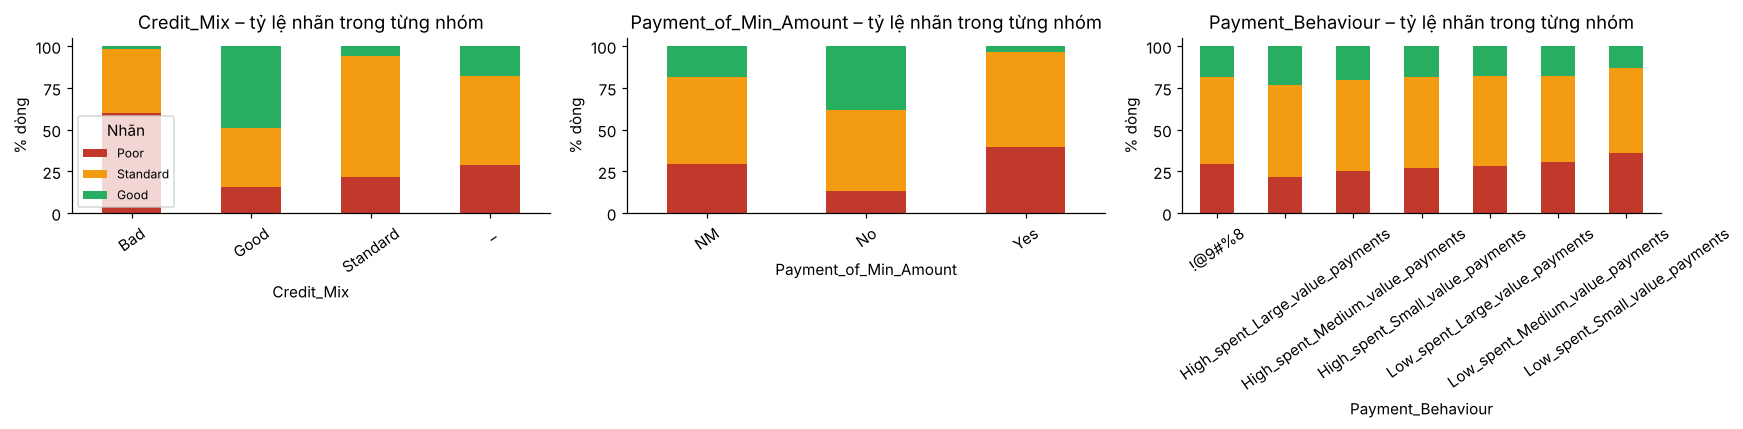

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, ['Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']):
    ct = pd.crosstab(df[c], df.Credit_Score, normalize='index')[ORDER] * 100
    ct.plot(kind='bar', stacked=True, ax=a, color=[PAL[k] for k in ORDER], rot=35, legend=False); a.set_ylabel('% dòng'); a.set_title(c + ' – tỷ lệ nhãn trong từng nhóm')
ax[0].legend(title='Nhãn', fontsize=8); plt.tight_layout(); plt.show()

`Credit_Mix = Bad` gần như tương ứng nhãn **Poor** và `Good` tương ứng **Good**; nhóm placeholder `_` có phân bố nhãn giống tỷ lệ chung (đúng như kiểm định ở 1.4.2) – tức là bị che mất thông tin vốn rất mạnh. Khôi phục nhóm này từ các tháng khác của cùng khách (vì `Credit_Mix` là hằng số theo khách) là rất có giá trị.

## 1.8 Tương quan giữa các đặc trưng số (Spearman)

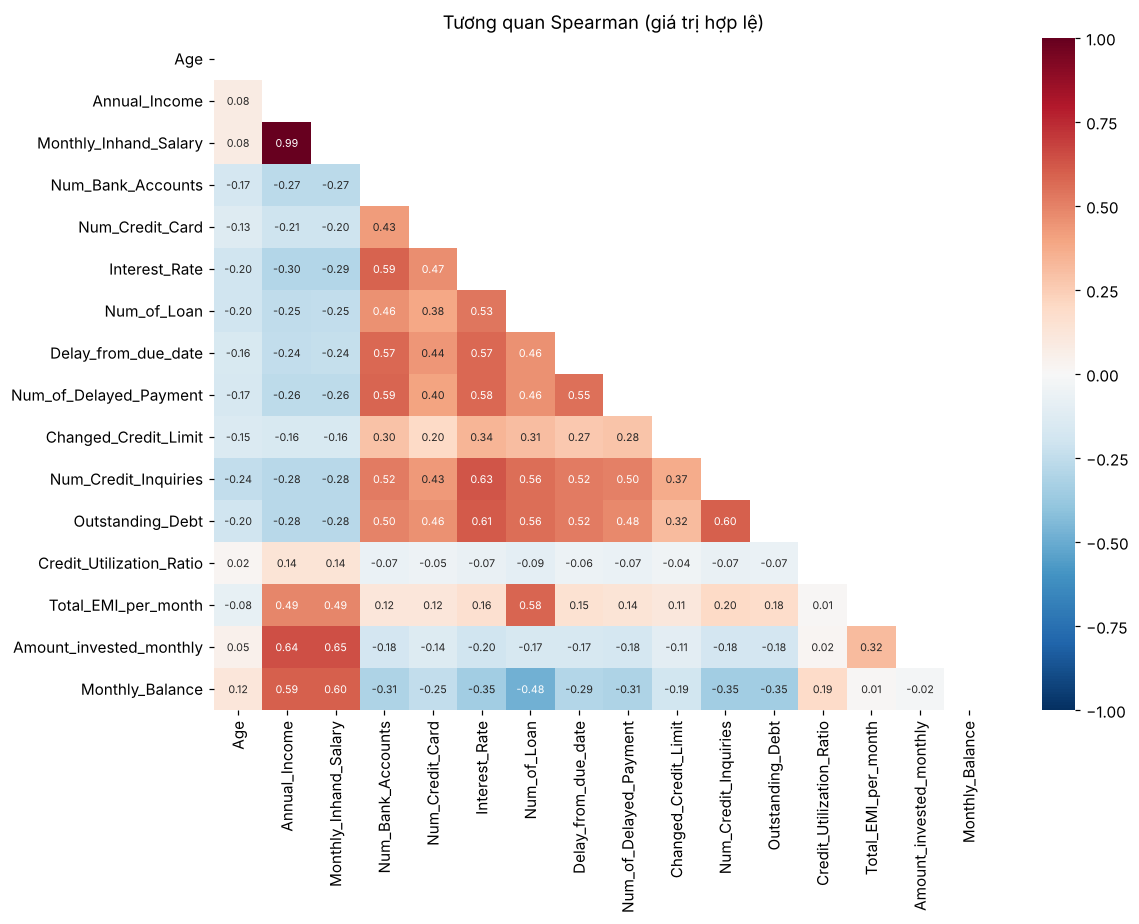

Cặp đặc trưng có |ρ| > 0,7:


,,ρ
Monthly_Inhand_Salary,Annual_Income,0.994


In [29]:
corr = v3[NUM].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(11, 8.5)); sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, vmin=-1, vmax=1)
plt.title('Tương quan Spearman (giá trị hợp lệ)'); plt.tight_layout(); plt.show()
pairs = corr.where(~mask).stack(); pairs = pairs[pairs.abs() > 0.7].sort_values(key=abs, ascending=False)
print('Cặp đặc trưng có |ρ| > 0,7:'); pairs.round(3).to_frame('ρ')

Ba nhóm quan hệ nổi bật:
1. `Annual_Income` ≈ `Monthly_Inhand_Salary` (ρ = 0,99, đa cộng tuyến) – không ảnh hưởng mô hình cây nhưng cần lưu ý khi diễn giải mô hình tuyến tính.
2. Một **cụm "rủi ro tín dụng"** (số tài khoản, số thẻ, lãi suất, số khoản vay, độ trễ, số lần trả chậm, truy vấn tín dụng, nợ tồn đọng) tương quan lẫn nhau ở mức 0,4–0,6.
3. `Amount_invested_monthly` và `Monthly_Balance` tương quan **0,6–0,65 với lương/thu nhập** nhưng gần như không tương quan với nhau (−0,02) → hai cột này *dự đoán được từ các cột khác của cùng dòng* – cơ sở để thử điền thiếu bằng mô hình (notebook 2).

Không có cặp nào đủ mạnh (ngoài cặp 1) để phải loại cột.

## 1.9 Tổng hợp mức độ bẩn: bao nhiêu dữ liệu bị ảnh hưởng?
Đếm số **ô** và số **dòng** có ít nhất một vấn đề (thiếu, placeholder, sai kiểu, giá trị vô lý) – để biết có thể "xóa dòng lỗi" được không.

Ô có vấn đề      : 135,774 / 2,800,000 (4.8%)
Dòng có ≥1 lỗi   : 76,333 / 100,000 (76.3%)
Khách có ≥1 lỗi  : 12,500 / 12,500


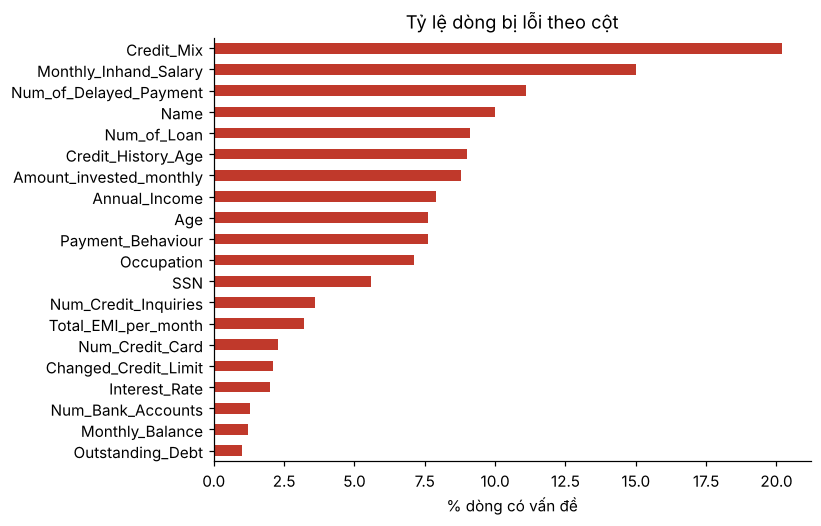

In [30]:
base = cc.add_month_num(df)
log = {}
stage_ph = cc.mark_placeholders(base, log)
stage_ty = cc.strip_numeric_text(stage_ph)
stage_inv = cc.mark_invalid(stage_ty, log)

problem = pd.DataFrame(False, index=df.index, columns=df.columns)
for c in df.columns:
    problem[c] = df[c].isna()
for c, t in cc.PLACEHOLDERS.items(): problem[c] |= (df[c] == t)
for c in cc.NUMERIC_TEXT_COLS: problem[c] |= df[c].astype(str).str.contains('_') & df[c].notna()
for c in ['Age', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Num_Credit_Inquiries', 'Total_EMI_per_month', 'Annual_Income']:
    problem[c] |= stage_inv[c].isna() & stage_ty[c].notna()
problem['Type_of_Loan'] = False      # trống = không có khoản vay (mục 1.3), không tính là lỗi
problem['Name'] = df['Name'].isna()

cells_bad = int(problem.values.sum()); cells_all = problem.size
rows_bad = int(problem.any(axis=1).sum())
print(f'Ô có vấn đề      : {cells_bad:,} / {cells_all:,} ({cells_bad / cells_all:.1%})')
print(f'Dòng có ≥1 lỗi   : {rows_bad:,} / {len(df):,} ({rows_bad / len(df):.1%})')
print(f'Khách có ≥1 lỗi  : {int(problem.any(axis=1).groupby(df.Customer_ID).any().sum()):,} / {df.Customer_ID.nunique():,}')
prob_col = problem.sum().sort_values(ascending=False); prob_col = prob_col[prob_col > 0]
(prob_col / len(df) * 100).round(1).sort_values().plot(kind='barh', figsize=(7, 5), color='#c0392b'); plt.xlabel('% dòng có vấn đề'); plt.title('Tỷ lệ dòng bị lỗi theo cột'); plt.show()

Đa số dòng có **ít nhất một** ô lỗi. Vậy **xóa dòng lỗi không phải lựa chọn khả thi** (mất gần hết dữ liệu, và có thể xóa lệch theo khách/nhãn) → bắt buộc phải **sửa/khôi phục** ô lỗi. (Mục này cũng cung cấp bảng "trước làm sạch" cho báo cáo chất lượng.)

In [31]:
# Lưu báo cáo chất lượng "TRƯỚC" làm sạch (dùng lại ở notebook 2)
import os; os.makedirs('../data/reports', exist_ok=True)
before = pd.DataFrame({
    'dtype_goc': df.dtypes.astype(str),
    'thieu': df.isna().sum(),
    'placeholder': [int((df[c] == cc.PLACEHOLDERS[c]).sum()) if c in cc.PLACEHOLDERS else 0 for c in df.columns],
    'vo_ly': [int((stage_inv[c].isna() & stage_ty[c].notna()).sum()) if c in stage_inv else 0 for c in df.columns],
    'dong_co_van_de': problem.sum(),
})
before['%_dong_co_van_de'] = (before['dong_co_van_de'] / len(df) * 100).round(2)
before.to_csv('../data/reports/quality_before.csv'); before[before.dong_co_van_de > 0]

,dtype_goc,thieu,placeholder,vo_ly,dong_co_van_de,%_dong_co_van_de
Name,str,9985,0,0,9985,9.98
Age,str,0,0,2781,7635,7.64
SSN,str,0,5572,0,5572,5.57
Occupation,str,0,7062,0,7062,7.06
Annual_Income,str,0,0,999,7929,7.93
Monthly_Inhand_Salary,float64,15002,0,0,15002,15.00
Num_Bank_Accounts,int64,0,0,1345,1345,1.34
Num_Credit_Card,int64,0,0,2320,2320,2.32
Interest_Rate,int64,0,0,2034,2034,2.03
Num_of_Loan,str,0,0,4348,9108,9.11


## 1.10 Từ phát hiện đến quyết định làm sạch

| # | Vấn đề | Bằng chứng (mục) | Quyết định | Hàm trong `credit_cleaning.py` |
|---|---|---|---|---|
| 1 | 7 cột có giá trị giả | 3 cách phát hiện độc lập (1.4.2); nhóm placeholder không mang thông tin nhãn | Đổi → NaN **trước** khi ép kiểu | `mark_placeholders` |
| 2 | 8 cột số lưu thành chữ dính `_` | 0 ô còn lại không đọc được sau khi bỏ `_` (1.4.1) | Bỏ `_` đầu/cuối rồi ép `float64` | `strip_numeric_text` |
| 3 | Cột đếm có giá trị ngoài miền | "Vách đá" tần suất, miền rút ra từ dữ liệu (1.5.1) | Ngoài miền → NaN | `mark_invalid` / `DOMAIN` |
| 4 | EMI rác | Chữ ký số nguyên; EMI thật ≤ 1.779 (1.5.2) | EMI > 1800 hoặc số nguyên dương → NaN | `mark_invalid` |
| 5 | `Annual_Income` rác | Lệch hàng bậc độ lớn so với chính khách (1.5.3) | Lệch > 50% so với trung vị khách → NaN | `mark_invalid` |
| 6 | **Không** dùng IQR chung | IQR xóa nhầm hàng nghìn giá trị thật ở 7 cột (1.5.4) | Chỉ áp luật cho cột có bằng chứng rác | – |
| 7 | Hằng số tuyệt đối theo khách | 1 giá trị/khách ở 12.500 khách (1.6) | Điền bằng mode/median **của khách** | `fill_categorical`, `fill_numeric('cust_median')` |
| 8 | Cột có "bước nhảy" thật | Thay đổi theo cặp, một lần (1.6) | Điền bằng **tháng gần nhất** | `nearest_fill` |
| 9 | `Num_of_Loan` rác | Khớp 100% số loại vay (1.6) | Suy ra từ `Type_of_Loan` | `repair` |
| 10 | `Credit_History_Age` thiếu, là chuỗi | Tăng đúng +1 tháng/tháng ở 100% khách (1.6) | Đổi ra số tháng; suy ô thiếu bằng số học | `parse_history_months`, `repair` |
| 11 | `Type_of_Loan` thiếu | Thiếu ⇔ `Num_of_Loan = 0` (1.3) | Điền `No Loan` | `repair` |
| 12 | `Amount_invested_monthly`, `Monthly_Balance` biến động mạnh | Phụ thuộc lương & hành vi chi tiêu (xem notebook 2) | Điền bằng mô hình học máy dự đoán **tỷ lệ so với lương** (thắng dự đoán giá trị tuyệt đối trong thí nghiệm) | `model_fill(ratio=True)` |
| 13 | `Payment_Behaviour` ngẫu nhiên theo tháng | Xem thí nghiệm notebook 2 | Giữ thành nhóm `Unknown` | `repair` |
| 14 | Xóa dòng lỗi không khả thi | Đa số dòng có ≥1 lỗi (1.9) | Sửa/khôi phục, không xóa | – |
| 15 | Nhãn lệch lớp; dữ liệu theo khách | Mục 1.2 | Chia train/test **theo khách**; dùng macro-F1 | notebook 4 |

→ **Notebook 2** thực hiện các quyết định trên, *kiểm chứng định lượng* từng quyết định (đặc biệt chiến lược điền thiếu) và xuất `credit_clean.csv`.